#### Notebook for comparing the PDE time evolution of a travelling wave with its analytical solutions

A periodic travelling wave $\phi(x-ct)$ of $u_t+\partial_x(\mathcal{L}u)+u\,u_x=0$ solves the profile equation
$(m(k)-c)\hat\phi+\tfrac12\widehat{\phi^2}=B$. We take $\phi$ and $c$ from the Newton solver, start the PDE solver (`KdV`, `Whitham`, integrated with `ifrk4`) from $\phi(x)$, and compare $u(x,t)$ with the exact solution over the same time steps.

**References**

| name | definition | used for |
|---|---|---|
| Cnoidal | $a+b\,\mathrm{cn}^2\!\big(\kappa(x-ct)\,\big \|\,m\big)$ from `kdv_cnoidal` | KdV only |
| Rigid translation | the Newton profile evaluated at $x-ct$ | KdV, Whitham |
| Fourier rotation | separation of variables, $\hat u_k(t)=\hat\phi_k\,e^{-ikct}$ | KdV, Whitham |

The last two are mathematically the same object (translating a periodic profile *is* rotating its Fourier phases), so they should agree to round-off. They are both included as a check of the machinery, and the notebook prints their mutual difference.

In [41]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [42]:
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton, WhithamNewton
from camera.pdeCamera import KdV, Whitham
from camera.help import *
from waves.soliton import kdv_cnoidal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Setup

The amplitude is the crest elevation above the mean, which is the quantity the Newton solver (`target_amp`) and `kdv_cnoidal` (`crest`$-$`mean`) both use.
All three amplitudes are used for both equations so the plots are comparable.

In [43]:
# Wave parameters
P    = 2*np.pi
N    = 2**7
mean = 0.0
amps = [0.1, 0.25, 0.5]

# Time stepping
dt         = 5e-3
T          = P/0.8
save_every = 20          # stored frames: every 0.1 time units

EQ = {
    "KdV":     dict(newton=KdVNewton,     pde=KdV),
    "Whitham": dict(newton=WhithamNewton, pde=Whitham),
}
REF_STYLE = {"Cnoidal": "-", "Rigid translation": "--", "Fourier rotation": ":"}

### Running one case

`run_case` does the following:

1. solves the Newton problem for the given crest, giving $\phi$, $c$;
2. starts the PDE solver from $\phi$ on the camera grid (`phi_hat_mid` puts the crest at $x=0$ on the symmetric grid, as in the cnoidal notebook) and integrates to $T$ with `ifrk4`;
3. builds the reference solutions at the saved times $t_n$.

Rigid translation is evaluated as the Fourier series of the Newton profile at the shifted points $x-ct$ (physical space), while Fourier rotation multiplies the discrete spectrum of $u_0$ by $e^{-ik c t}$ and transforms back (spectral space).
If `brentq` in `kdv_cnoidal` fails for some amplitude, the cnoidal reference is skipped for that case.

In [44]:
def run_case(kind, amp, P=P, N=N, mean=mean, dt=dt, T=T, save_every=save_every):
    cfg = EQ[kind]
    cam = Camera(P, N, dt)

    # Newton: crest = amp + mean
    wp = cfg["newton"](P, amp + mean, mean, cam)
    wp.solve_w_continuation()
    c    = wp.c
    phi0 = wp.get_physical(wp.phi_hat_mid)        # crest at x = 0 on cam.x

    # PDE
    solver = cfg["pde"](camera=cam, T=T, u0=phi0, save_every=save_every)
    t, u   = solver.ifrk4()

    refs = {}

    # Fourier rotation: u_hat_k(t) = u_hat_k(0) exp(-i k c t)
    u0_hat = np.fft.fft(phi0)
    refs["Fourier rotation"] = np.fft.ifft(
        u0_hat[None, :]*np.exp(-1j*cam.k[None, :]*c*t[:, None]), axis=1).real

    # Rigid translation: Newton Fourier series (crest at x=0) evaluated at x - c t
    kr  = 2*np.pi*np.fft.rfftfreq(N, d=cam.dx)
    arg = np.exp(1j*kr[None, None, :]*(cam.x[None, :, None] - c*t[:, None, None]))
    refs["Rigid translation"] = np.real(np.sum(wp.hw*wp.phi_hat*arg, axis=2))

    out = dict(kind=kind, amp=amp, cam=cam, wp=wp, solver=solver, c=c, t=t, u=u,
               phi0=phi0, refs=refs, m=None, c_cn=None)

    if kind == "KdV":
        try:
            phi_cn, c_cn, m = kdv_cnoidal(P=P, crest=amp + mean, mean=mean, x=cam.x, t=t)
            refs["Cnoidal"] = phi_cn
            out["m"], out["c_cn"] = m, c_cn
        except Exception as e:
            print(f"cnoidal skipped for amp = {amp}: {e}")

    # keep the cnoidal reference first in the legend
    out["refs"] = {k: refs[k] for k in REF_STYLE if k in refs}
    return out


def error_norms(u, ref, dx):
    d = u - ref
    return np.max(np.abs(d), axis=1), np.sqrt(dx*np.sum(d**2, axis=1))


def run_all(kind):
    res = {a: run_case(kind, a) for a in amps}
    rows = []
    for a, r in res.items():
        for name, ref in r["refs"].items():
            linf, l2 = error_norms(r["u"], ref, r["cam"].dx)
            rows.append((a, name, linf[-1], linf.max(), l2[-1]))
    df = pd.DataFrame(rows, columns=["amp", "reference", "Linf(T)", "max_t Linf", "L2(T)"])
    return res, df

### Plotting helpers

In [45]:
def plot_snapshots(res, n_show=3):
    # PDE (thick) against each reference (thin) at a few times; the t = 0 profile in grey
    kind = next(iter(res.values()))["kind"]
    fig, axes = plt.subplots(len(res), n_show, figsize=(4.2*n_show, 2.8*len(res)), sharex=True, squeeze=False)
    for row, (a, r) in zip(axes, res.items()):
        t = r["t"]; x = r["cam"].x
        idx = [int(round(len(t)*(j+1)/n_show)) - 1 for j in range(n_show)]
        for ax, n in zip(row, idx):
            ax.plot(x, r["u"][0], color="0.75", lw=1, label="$t=0$")
            ax.plot(x, r["u"][n], color="C0", lw=4, alpha=0.35, label="PDE")
            for name, ref in r["refs"].items():
                ax.plot(x, ref[n], REF_STYLE[name], lw=1.6, label=name)
            ax.set_title(f"amp = {a},  t = {t[n]:.2f}")
            ax.grid(True)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=len(l), fontsize=9)
    for ax in axes[-1]: ax.set_xlabel("x")
    for ax in axes[:, 0]: ax.set_ylabel(r"$u(x,t)$")
    fig.suptitle(f"{kind}: PDE against the analytical solutions", y=1.0)
    plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()


def plot_error_time(res):
    kind = next(iter(res.values()))["kind"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
    for i, (a, r) in enumerate(res.items()):
        for name, ref in r["refs"].items():
            linf, l2 = error_norms(r["u"], ref, r["cam"].dx)
            lab = f"amp = {a}, {name}"
            axes[0].semilogy(r["t"], linf + 1e-18, REF_STYLE[name], color=f"C{i}", label=lab)
            axes[1].semilogy(r["t"], l2   + 1e-18, REF_STYLE[name], color=f"C{i}", label=lab)
    axes[0].set_title(rf"{kind}: $L^\infty$ error"); axes[1].set_title(rf"{kind}: $L^2$ error")
    for ax in axes: ax.set_xlabel("t"); ax.grid(True)
    axes[0].legend(fontsize=7, ncol=1)
    plt.tight_layout(); plt.show()


def plot_error_heatmaps(res, which):
    # signed space-time error PDE - reference
    kind = next(iter(res.values()))["kind"]
    fig, axes = plt.subplots(len(res), len(which), figsize=(5.5*len(which), 2.9*len(res)), squeeze=False, sharex=True)
    for row, (a, r) in zip(axes, res.items()):
        x = r["cam"].x; dx = r["cam"].dx
        for ax, name in zip(row, which):
            if name not in r["refs"]:
                ax.set_visible(False); continue
            err = r["u"] - r["refs"][name]
            v = max(np.max(np.abs(err)), 1e-18)
            im = ax.imshow(err, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v,
                           extent=[x[0], x[-1] + dx, 0, r["t"][-1]])
            ax.set_title(f"amp = {a}:  PDE $-$ {name}")
            fig.colorbar(im, ax=ax, format="%.1e")
    for ax in axes[-1]: ax.set_xlabel("x")
    for ax in axes[:, 0]: ax.set_ylabel("t")
    fig.suptitle(f"{kind}: space-time error", y=1.0)
    plt.tight_layout(); plt.show()


def plot_mode_drift(res, modes=(1, 2, 3, 4)):
    # ratio_k(t) = u_hat_k(t) / (u_hat_k(0) exp(-i k c t)) ;  |ratio|-1 is the amplitude drift, arg(ratio) the phase drift
    kind = next(iter(res.values()))["kind"]
    fig, axes = plt.subplots(len(res), 2, figsize=(11, 2.9*len(res)), sharex=True, squeeze=False)
    for row, (a, r) in zip(axes, res.items()):
        t = r["t"]; cam = r["cam"]
        uh = np.fft.fft(r["u"], axis=1)/cam.N
        for j in modes:
            k = cam.k[j]
            ratio = uh[:, j]/(uh[0, j]*np.exp(-1j*k*r["c"]*t))
            row[0].semilogy(t, np.abs(np.abs(ratio) - 1) + 1e-18, label=f"k = {k:.0f}")
            row[1].semilogy(t, np.abs(np.angle(ratio))   + 1e-18, label=f"k = {k:.0f}")
        row[0].set_title(f"amp = {a}: |amplitude drift|")
        row[1].set_title(f"amp = {a}: |phase drift| (rad)")
        for ax in row: ax.grid(True)
    axes[0, 0].legend(fontsize=8)
    for ax in axes[-1]: ax.set_xlabel("t")
    fig.suptitle(f"{kind}: Fourier modes of the PDE solution relative to the rotation", y=1.0)
    plt.tight_layout(); plt.show()


def translation_vs_rotation(res):
    return pd.DataFrame({a: [np.max(np.abs(r["refs"]["Rigid translation"] - r["refs"]["Fourier rotation"]))]
                         for a, r in res.items()}, index=["max |translation - rotation|"])

## KdV

$m(k)=1-k^2/6$. Three references: the cnoidal wave, the rigid translation and the Fourier rotation.

In [46]:
kdv_res, kdv_df = run_all("KdV")

print(pd.DataFrame(
    [(a, r["m"], r["c"], r["c_cn"], abs(r["c"] - r["c_cn"]) if r["c_cn"] is not None else np.nan) for a, r in kdv_res.items()],
    columns=["amp", "m (cnoidal)", "c Newton", "c cnoidal", "|c diff|"]
).to_string(index=False, float_format=lambda v: f"{v:.10g}"))

 amp  m (cnoidal)     c Newton    c cnoidal  |c diff|
 0.1 0.3169999567 0.8356050033 0.8356050033         0
0.25 0.5906252486 0.8458096553 0.8458096553         0
 0.5 0.8035342591  0.874842828  0.874842828         0


### Snapshots

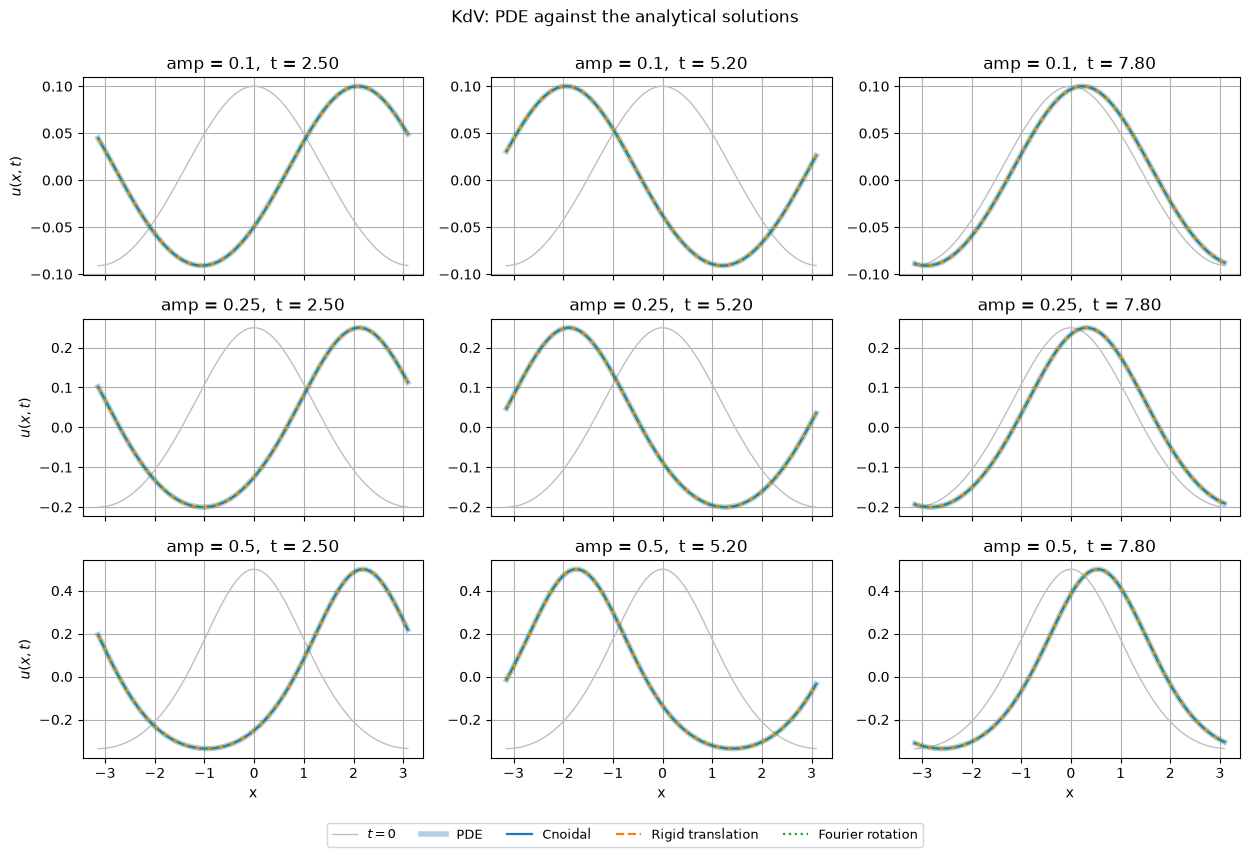

In [47]:
plot_snapshots(kdv_res)

### Error against time

The errors are far below plotting resolution in the snapshots, so they are shown on a log scale. The error does not grow steadily: it appears within the first stored interval and then stays bounded, and its level increases with amplitude. A wrong wave speed would instead give an error growing linearly in $t$.

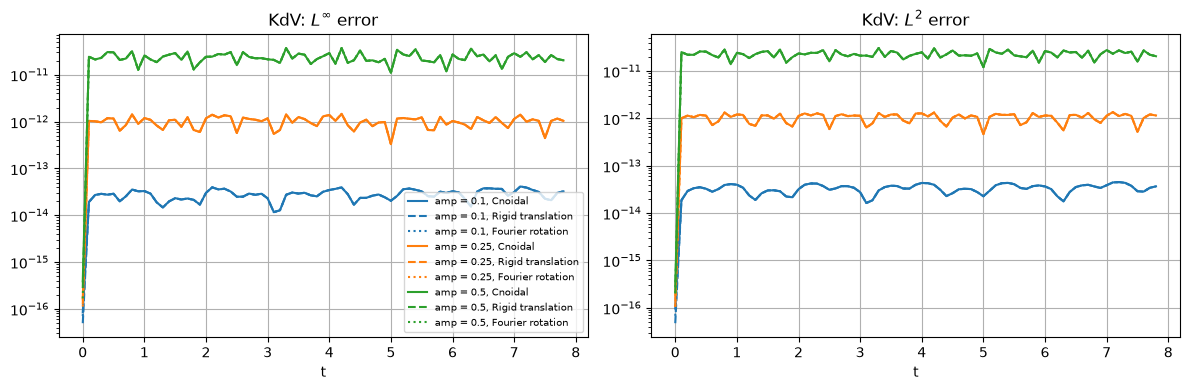

In [48]:
plot_error_time(kdv_res)

### Space-time error

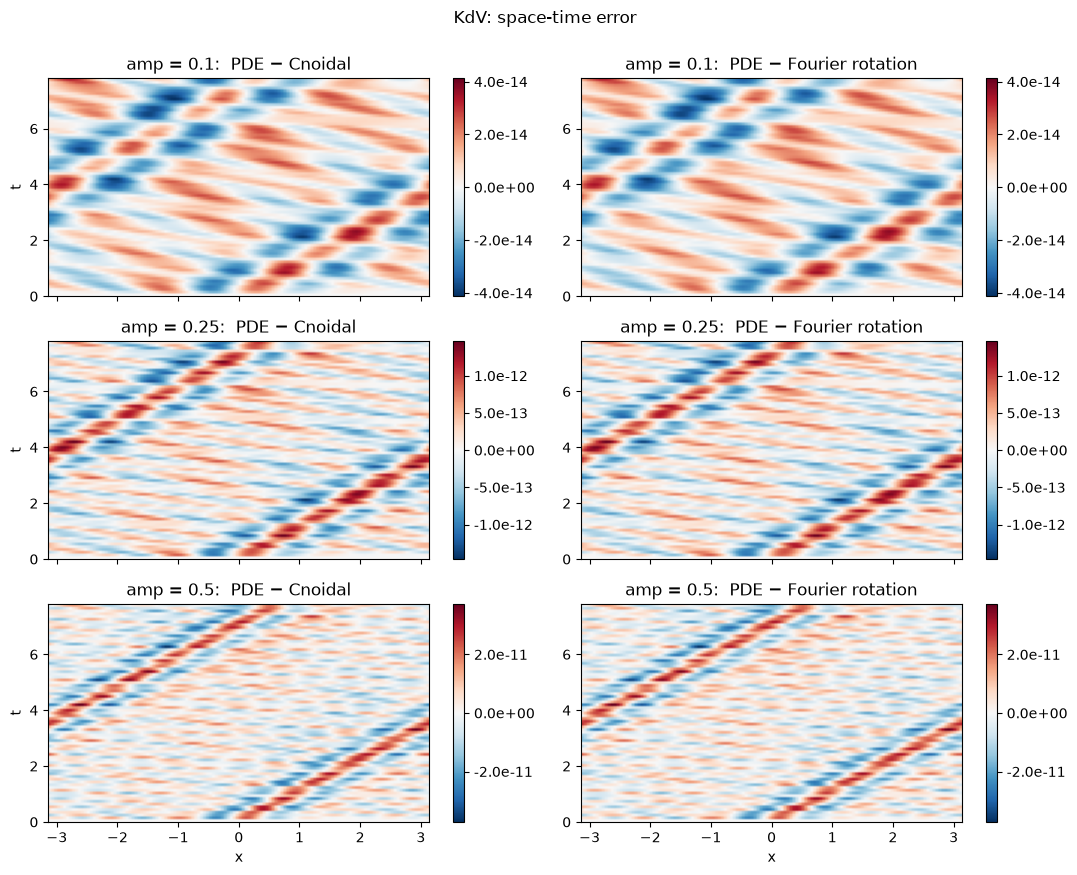

In [49]:
plot_error_heatmaps(kdv_res, ["Cnoidal", "Fourier rotation"])

### Fourier modes: amplitude and phase drift

Relative to the exact rotation each mode should keep its modulus and advance its phase by exactly $-kct$. A systematic drift in the phase would mean that the PDE solver's effective wave speed differs from the Newton $c$. The drift is a *relative* quantity, so the higher modes (whose amplitudes are tiny) look larger than the dominant ones.

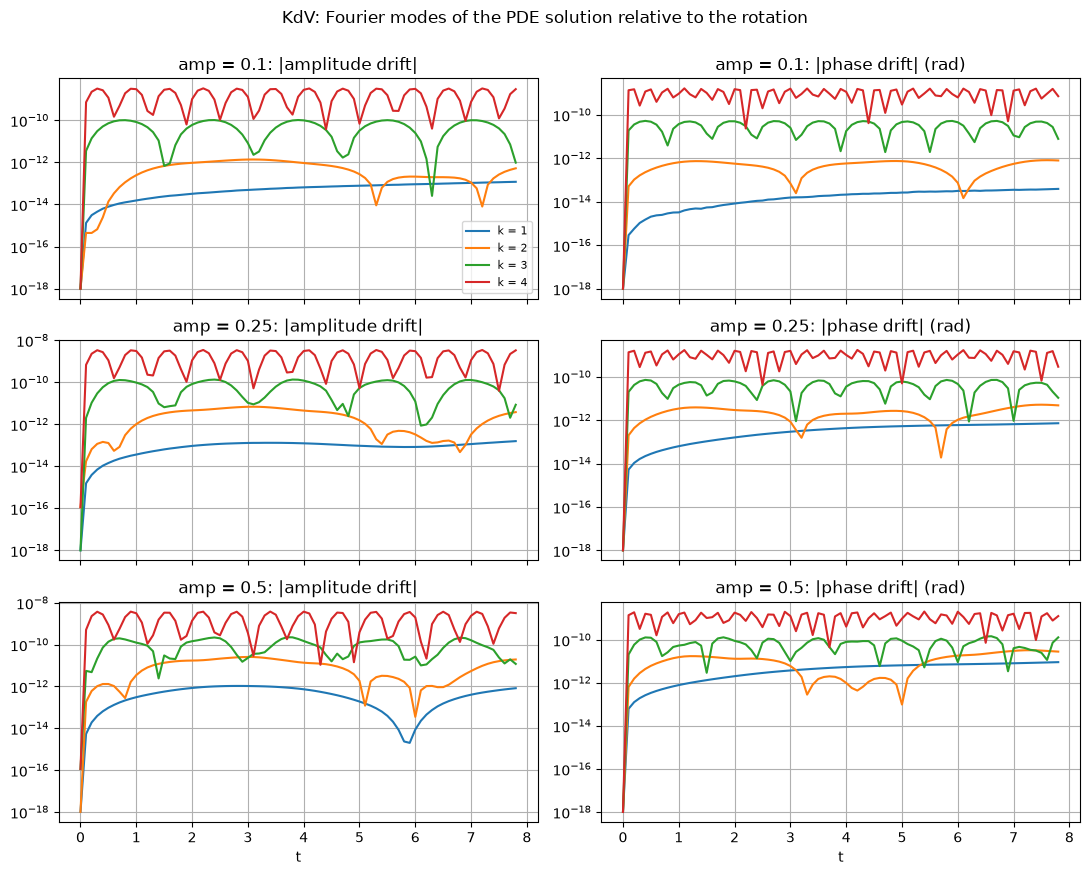

In [50]:
plot_mode_drift(kdv_res)

### Translation against rotation (should be round-off) and final-time errors

In [51]:
display(translation_vs_rotation(kdv_res).style.format("{:.2e}"))
print(kdv_df.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

,0.100000,0.250000,0.500000
max |translation - rotation|,1.25e-16,2.78e-16,5.00e-16


      amp         reference   Linf(T)  max_t Linf     L2(T)
1.000e-01           Cnoidal 3.243e-14   4.126e-14 3.679e-14
1.000e-01 Rigid translation 3.236e-14   4.122e-14 3.672e-14
1.000e-01  Fourier rotation 3.240e-14   4.124e-14 3.675e-14
2.500e-01           Cnoidal 1.040e-12   1.464e-12 1.157e-12
2.500e-01 Rigid translation 1.040e-12   1.464e-12 1.157e-12
2.500e-01  Fourier rotation 1.040e-12   1.464e-12 1.157e-12
5.000e-01           Cnoidal 2.044e-11   3.723e-11 2.064e-11
5.000e-01 Rigid translation 2.044e-11   3.723e-11 2.064e-11
5.000e-01  Fourier rotation 2.044e-11   3.723e-11 2.064e-11


### Conservation

Mass is $\approx 0$ for `mean = 0`, so its *relative* error is not meaningful. Read the absolute one.

In [52]:
for a, r in kdv_res.items():
    print(f"\n=========== KdV, amp = {a} ===========")
    r["solver"].conservation()


=========== KdV, amp = 0.1 ===========
----- Conservation of  Mass -----
Initial Mass: 7.49e-18
Final Mass: -2.04e-18
Maximum error: 2.42e-17
Relative error: 3.23e+00
------------------------------
----- Conservation of  L2 -----
Initial L2: 2.86e-02
Final L2: 2.86e-02
Maximum error: 6.73e-15
Relative error: 2.35e-13
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 1.19e-02
Final Hamiltonian: 1.19e-02
Maximum error: 2.82e-15
Relative error: 2.36e-13
------------------------------

=========== KdV, amp = 0.25 ===========
----- Conservation of  Mass -----
Initial Mass: -1.09e-17
Final Mass: 1.36e-17
Maximum error: 4.94e-17
Relative error: 4.53e+00
------------------------------
----- Conservation of  L2 -----
Initial L2: 1.58e-01
Final L2: 1.58e-01
Maximum error: 3.44e-14
Relative error: 2.17e-13
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 6.64e-02
Final Hamiltonian: 6.64e-02
Maximum error: 1.45

## Whitham

$m(k)=\sqrt{\tanh k/k}$. There is no closed-form cnoidal wave here, so the references are the rigid translation of the Newton profile and the Fourier rotation, as above.

In [53]:
wh_res, wh_df = run_all("Whitham")

print(pd.DataFrame([(a, r["c"]) for a, r in wh_res.items()], columns=["amp", "c Newton"]).to_string(index=False, float_format=lambda v: f"{v:.10g}"))

 amp     c Newton
 0.1 0.8781710373
0.25 0.8982707022
 0.5 0.9408795895


### Snapshots

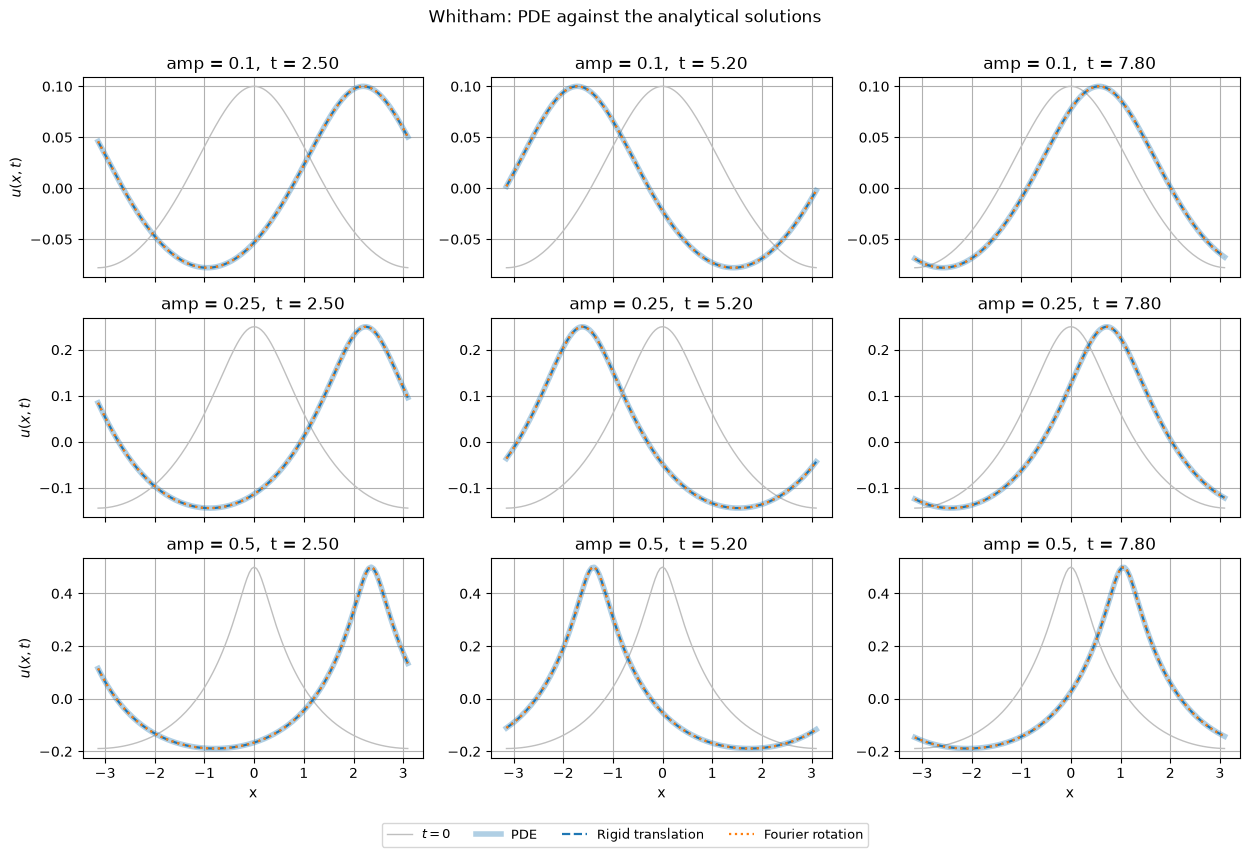

In [54]:
plot_snapshots(wh_res)

### Error against time

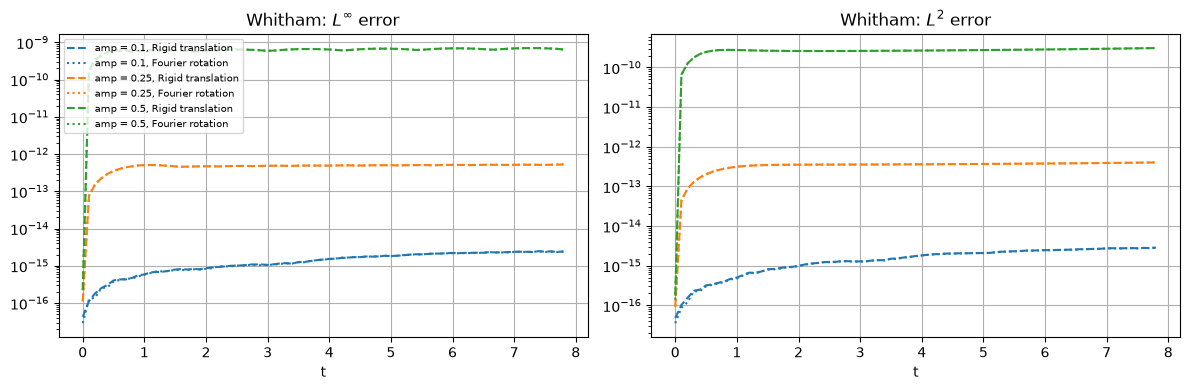

In [55]:
plot_error_time(wh_res)

### Space-time error

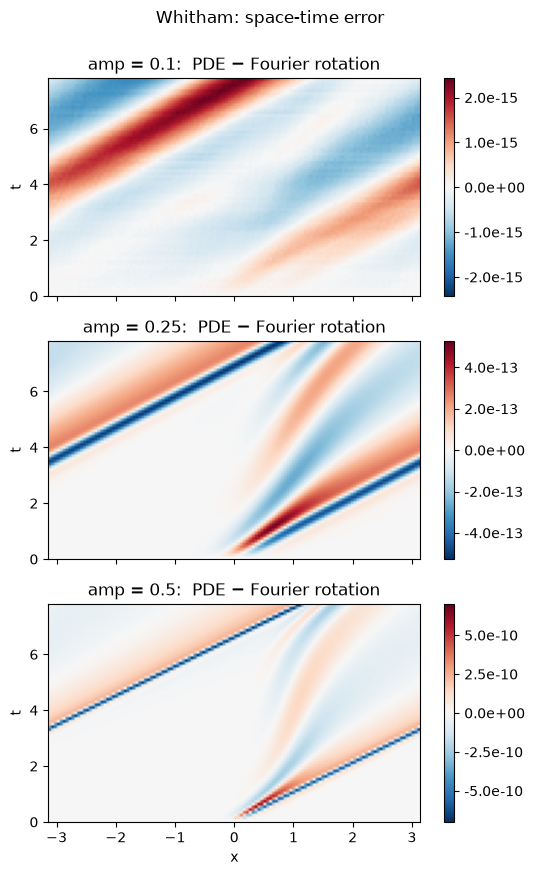

In [56]:
plot_error_heatmaps(wh_res, ["Fourier rotation"])

### Fourier modes: amplitude and phase drift

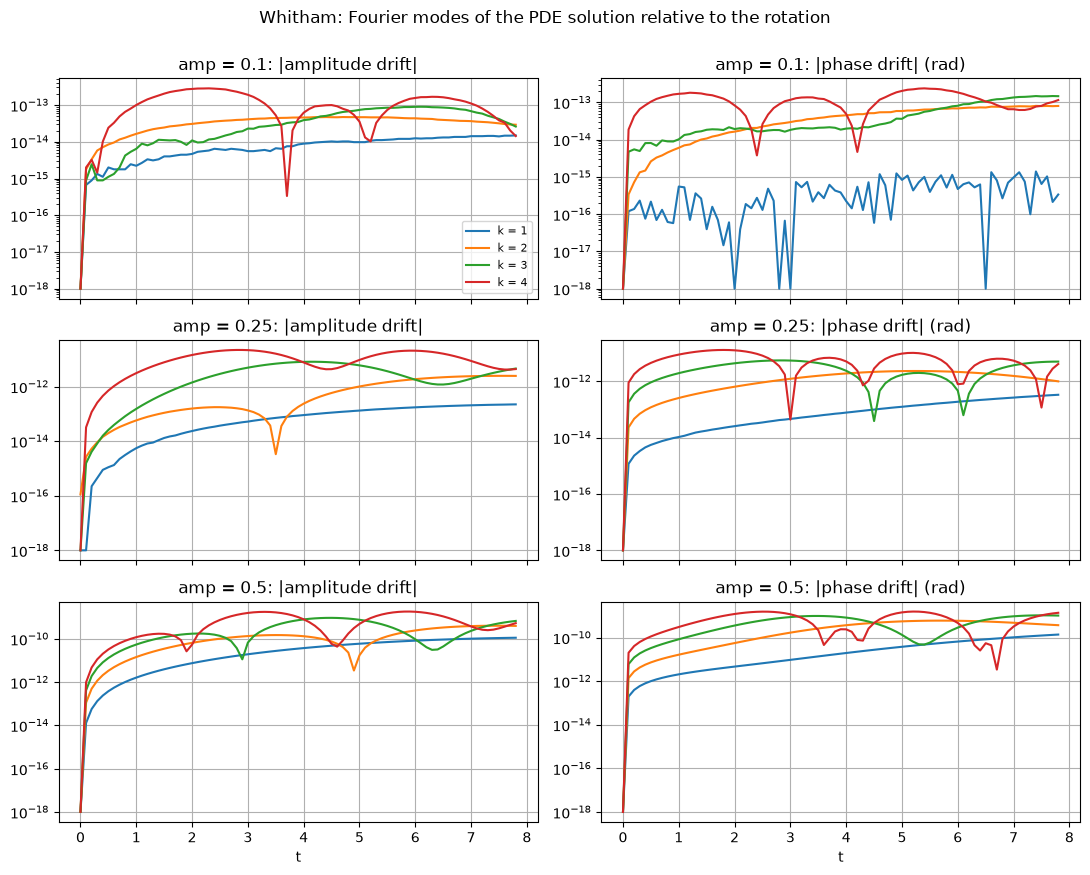

In [57]:
plot_mode_drift(wh_res)

### Translation against rotation and final-time errors

In [58]:
display(translation_vs_rotation(wh_res).style.format("{:.2e}"))
print(wh_df.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

,0.100000,0.250000,0.500000
max |translation - rotation|,9.71e-17,2.78e-16,7.22e-16


      amp         reference   Linf(T)  max_t Linf     L2(T)
1.000e-01 Rigid translation 2.442e-15   2.470e-15 2.858e-15
1.000e-01  Fourier rotation 2.401e-15   2.429e-15 2.836e-15
2.500e-01 Rigid translation 5.267e-13   5.267e-13 4.025e-13
2.500e-01  Fourier rotation 5.267e-13   5.267e-13 4.025e-13
5.000e-01 Rigid translation 6.437e-10   7.002e-10 3.087e-10
5.000e-01  Fourier rotation 6.437e-10   7.002e-10 3.087e-10


### Conservation

In [59]:
for a, r in wh_res.items():
    print(f"\n=========== Whitham, amp = {a} ===========")
    r["solver"].conservation()


=========== Whitham, amp = 0.1 ===========
----- Conservation of  Mass -----
Initial Mass: 0.00e+00
Final Mass: -3.41e-18
Maximum error: 1.87e-17
Relative error: inf
------------------------------
----- Conservation of  L2 -----
Initial L2: 2.43e-02
Final L2: 2.43e-02
Maximum error: 7.42e-16
Relative error: 3.05e-14
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 1.06e-02
Final Hamiltonian: 1.06e-02
Maximum error: 3.24e-16
Relative error: 3.05e-14
------------------------------

=========== Whitham, amp = 0.25 ===========
----- Conservation of  Mass -----
Initial Mass: -5.45e-18
Final Mass: -4.09e-18
Maximum error: 3.13e-17
Relative error: 5.75e+00
------------------------------
----- Conservation of  L2 -----
Initial L2: 1.09e-01
Final L2: 1.09e-01
Maximum error: 3.55e-15
Relative error: 3.25e-14
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 4.84e-02
Final Hamiltonian: 4.84e-02
Maximum error: 

c:\Users\henri\Documents\progging\Prosjekt_Master\camera\help.py:205: RuntimeWarning: divide by zero encountered in scalar divide
  print(f"Relative error: {((np.max(np.abs(unit -unit[0]))/np.abs(unit[0]).real)):.2e}")


### KdV against Whitham

Final-time $L^\infty$ error with respect to the Fourier rotation for the same amplitudes.

In [60]:
cmp_df = pd.DataFrame({
    "KdV":     kdv_df[kdv_df.reference == "Fourier rotation"].set_index("amp")["Linf(T)"],
    "Whitham": wh_df [wh_df.reference  == "Fourier rotation"].set_index("amp")["Linf(T)"],
})
print(cmp_df.to_string(float_format=lambda v: f"{v:.3e}"))

           KdV   Whitham
amp                     
0.10 3.240e-14 2.401e-15
0.25 1.040e-12 5.267e-13
0.50 2.044e-11 6.437e-10
